# Bank card fraud detection — starter notebook

Predict `fraud_probability` for every row of `test.csv`. Scoring is **ROC AUC**, so only the ranking matters.

About 1.4% of transactions are fraudulent, the test period comes after the training period (days 1–36 train, 37–60 test), and the useful signals are relative to each customer's own history. Some fraud is never reported, so the labels are noisy and the ceiling is around 0.94 — this baseline gets ~0.91. Merchant/device risk is the main headroom.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 0
DATA = Path("/kaggle/input/competitions/dads-10")
if not DATA.exists():
    DATA = Path("data")

train = pd.read_csv(DATA / "train.csv", parse_dates=["timestamp"])
test = pd.read_csv(DATA / "test.csv", parse_dates=["timestamp"])
print(f"train {train.shape} | test {test.shape} | fraud {train.is_fraud.mean():.2%}")
print("train", train.timestamp.min().date(), "->", train.timestamp.max().date())
print("test ", test.timestamp.min().date(), "->", test.timestamp.max().date())
print("cards:", train.card_id.nunique(), "train /", test.card_id.nunique(), "test")

train (60197, 20) | test (39803, 19) | fraud 1.33%
train 2026-01-01 -> 2026-02-05
test  2026-02-06 -> 2026-03-02
cards: 6711 train / 6347 test


## 1. Quick look

Fraud concentrates in a few merchant categories and some hours of the day, and its amounts overlap heavily with legitimate spending — a single-column rule will not work.

                   mean  size
merchant_category            
gambling            4.1  2471
digital             3.4  5471
crypto              3.2  1555
electronics         2.7  3606
travel              2.5  2380
retail              2.3  8819


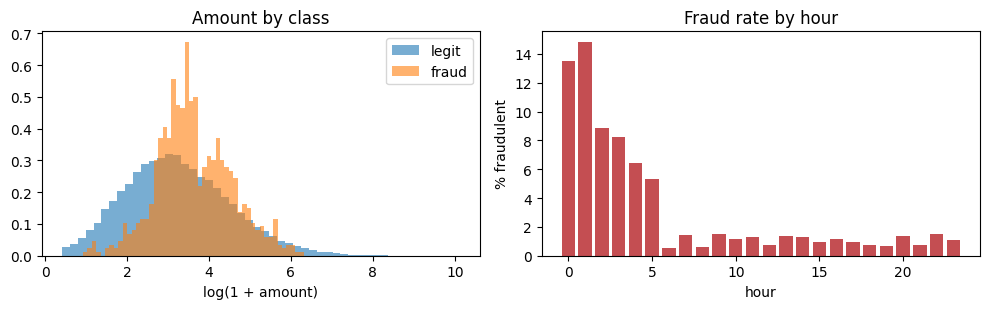

In [6]:
cats = train.groupby("merchant_category").is_fraud.agg(["mean", "size"])
cats = cats.sort_values("mean", ascending=False).head(6)
cats["mean"] = (cats["mean"] * 100).round(1)
print(cats.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for label, name in [(0, "legit"), (1, "fraud")]:
    axes[0].hist(np.log1p(train.loc[train.is_fraud == label, "amount"]),
                 bins=50, density=True, alpha=0.6, label=name)
    
axes[0].set(xlabel="log(1 + amount)", title="Amount by class")
axes[0].legend()
hourly = train.assign(hour=train.timestamp.dt.hour).groupby("hour").is_fraud.mean() * 100
axes[1].bar(hourly.index, hourly.values, color="#c44e52")
axes[1].set(xlabel="hour", ylabel="% fraudulent", title="Fraud rate by hour")
plt.tight_layout()

## 2. Feature engineering

Everything below is label-free, so it is computed on `train + test` together. The point is context per card: spend relative to that card's history, velocity, and first-time-seen device/merchant/country.

In [7]:
def rolling_count(s, window):
    t = s.values.astype("datetime64[s]").astype(np.int64)
    return pd.Series(np.arange(1, len(t) + 1) - np.searchsorted(t, t - window), index=s.index)


def build_features(train, test):
    df = pd.concat([train.drop(columns=["is_fraud"]), test], ignore_index=True)
    df = df.sort_values("timestamp").reset_index(drop=True)
    df["hour"] = df.timestamp.dt.hour
    df["day_of_week"] = df.timestamp.dt.dayofweek
    df["is_night"] = df.hour.isin([0, 1, 2, 3, 4, 5]).astype(int)
    df["is_weekend"] = (df.day_of_week >= 5).astype(int)
    df["log_amount"] = np.log1p(df.amount)
    df["card_present"] = df.card_present.astype(int)

    g = df.groupby("card_id")
    df["card_amount_mean"] = g.amount.transform("mean")
    df["card_amount_std"] = g.amount.transform("std")
    df["amount_vs_card"] = df.amount / df.card_amount_mean
    df["amount_z"] = (df.amount - df.card_amount_mean) / df.card_amount_std.fillna(1)
    df["card_txn_count"] = g.transaction_id.transform("count")
    df["card_merchant_count"] = g.merchant_id.transform("nunique")
    df["merchant_txn_count"] = df.groupby("merchant_id").transaction_id.transform("count")

    df = df.sort_values(["card_id", "timestamp"])
    g = df.groupby("card_id")
    df["seconds_since_prev"] = g.timestamp.diff().dt.total_seconds()
    df["txn_last_1h"] = g.timestamp.transform(lambda s: rolling_count(s, 3600))
    df["txn_last_1d"] = g.timestamp.transform(lambda s: rolling_count(s, 86400))
    df["is_new_device"] = (~df.duplicated(["card_id", "device_id"]) & df.device_id.notna()).astype(int)
    df["is_new_merchant"] = (~df.duplicated(["card_id", "merchant_id"])).astype(int)
    df["is_new_country"] = (~df.duplicated(["card_id", "merchant_country"])).astype(int)
    return df.sort_values("timestamp").reset_index(drop=True)


df = build_features(train, test)
df["is_train"] = df.transaction_id.isin(train.transaction_id)
df["is_fraud"] = df.transaction_id.map(train.set_index("transaction_id").is_fraud)

CATEGORICALS = ["channel", "merchant_category", "customer_home_country",
                "merchant_country", "ip_country"]
for col in CATEGORICALS:
    df[col] = df[col].astype("category").cat.codes

FEATURES = [
    "amount", "log_amount", "amount_vs_card", "amount_z", "card_amount_mean",
    "card_amount_std", "card_txn_count", "card_merchant_count", "hour",
    "day_of_week", "is_night", "is_weekend", "card_present",
    "is_foreign_merchant", "is_foreign_ip", "customer_age", "account_age_days",
    "txn_last_1h", "txn_last_1d", "seconds_since_prev", "is_new_device",
    "is_new_merchant", "is_new_country",
] + CATEGORICALS
# merchant_txn_count is built but left out on purpose: merchant risk is the
# biggest source of headroom. Try encoding it without leaking labels.

X = df.loc[df.is_train, FEATURES].fillna(-1)
X_test = df.loc[~df.is_train, FEATURES].fillna(-1)
y = df.loc[df.is_train, "is_fraud"].to_numpy().astype(int)
test_ids = df.loc[~df.is_train, "transaction_id"].to_numpy()
print(X.shape, X_test.shape)

(60197, 28) (39803, 28)


## 3. Baseline model, CV and submission

`HistGradientBoostingClassifier` handles mixed numeric/categorical data without scaling, and AUC does not care about calibration.

In [8]:
def make_model():
    return HistGradientBoostingClassifier(
        max_iter=600, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20,
        l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
        random_state=RANDOM_STATE)

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

aucs = []
for k, (tr, va) in enumerate(cv.split(X, y), start=1):
    p = make_model().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])[:, 1]
    aucs.append(roc_auc_score(y[va], p))
    print(f"fold {k}: AUC = {aucs[-1]:.4f}")
    
print(f"mean CV AUC = {np.mean(aucs):.4f} +/- {np.std(aucs):.4f}")

model = make_model().fit(X, y)
pred = model.predict_proba(X_test)[:, 1]

pd.DataFrame({"transaction_id": test_ids, "fraud_probability": pred}).to_csv(
    "submission.csv", index=False)

print(f"submission.csv written | {len(pred)} rows | "
      f"predicted fraud rate @0.5: {(pred > 0.5).mean():.3%}")

fold 1: AUC = 0.9216
fold 2: AUC = 0.9276
fold 3: AUC = 0.9293
fold 4: AUC = 0.9181
fold 5: AUC = 0.9053
mean CV AUC = 0.9204 +/- 0.0086
submission.csv written | 39803 rows | predicted fraud rate @0.5: 0.359%
